<a href="https://colab.research.google.com/github/muhammadreshmaramadhan-lang/PCD_Assignment02/blob/main/PCD_Assignment02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

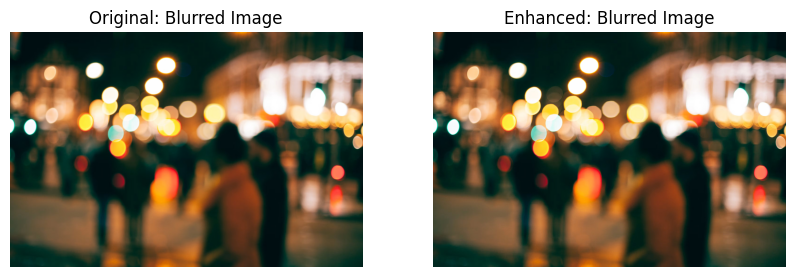

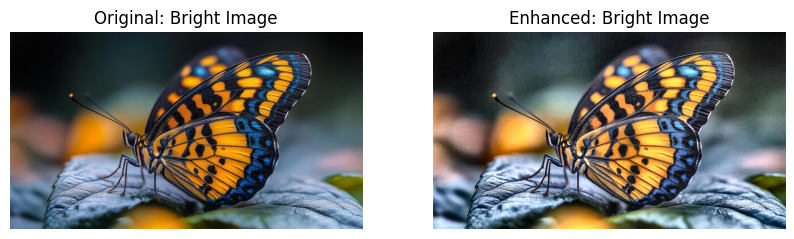

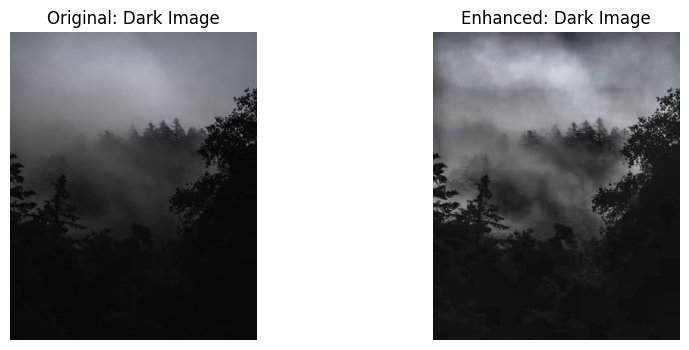

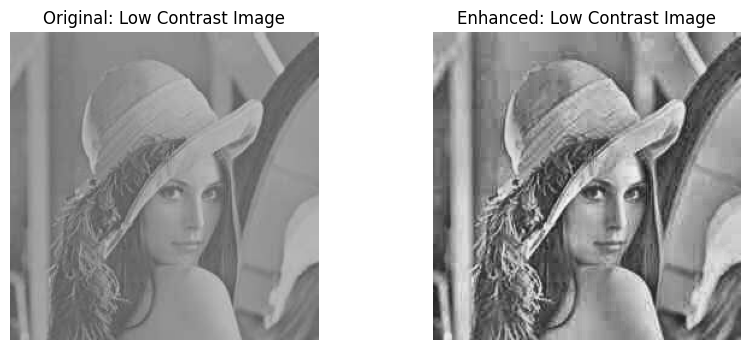

In [2]:
import cv2
import matplotlib.pyplot as plt

img_blur = cv2.imread('blurred.jpg')
img_bright = cv2.imread('bright.jpg')
img_dark = cv2.imread('dark.jpg')
img_low = cv2.imread('low contrast.jpg')

blur_smooth = cv2.GaussianBlur(img_blur, (0, 0), 3)
enhanced_blur = cv2.addWeighted(img_blur, 1.5, blur_smooth, -0.5, 0)

clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))

def enhance_image(img):
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    l = clahe.apply(l)
    result = cv2.merge((l, a, b))
    return cv2.cvtColor(result, cv2.COLOR_LAB2BGR)

enhanced_bright = enhance_image(img_bright)
enhanced_dark = enhance_image(img_dark)
enhanced_low = enhance_image(img_low)

image_list = [
    ("Blurred Image", img_blur, enhanced_blur),
    ("Bright Image", img_bright, enhanced_bright),
    ("Dark Image", img_dark, enhanced_dark),
    ("Low Contrast Image", img_low, enhanced_low)
]

for title, original, enhanced in image_list:
    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
    plt.title("Original: " + title)
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(cv2.cvtColor(enhanced, cv2.COLOR_BGR2RGB))
    plt.title("Enhanced: " + title)
    plt.axis('off')

    plt.show()

# Image Enhancement Analysis Report

**Course:** Digital Image Processing  
**Assignment:** PCD_Assignment02  
**Name:** Muhammad Reshma Ramadhan  
**NIM:** 25/555071/PA/23258  



## 1. Introduction
Image enhancement is an important process in digital image processing. Its main goal is to improve the visual quality of an image so that human eyes or computer systems can see details more clearly. In real life, photos often suffer from lighting and quality issues, such as being too dark, overexposed (too bright), blurry, or having low contrast. This report presents the implementation and analysis of image enhancement techniques on four different types of image degradations using Python and OpenCV.



## 2. Methodology
Two main methods were used to fix the four image problems:

1. **Contrast Limited Adaptive Histogram Equalization (CLAHE):**
   * **Used for:** Dark, Bright, and Low-Contrast images.
   * **How it works:** Standard histogram equalization changes the whole image at once, which often creates unnatural noise. CLAHE solves this by dividing the image into small sections (tiles) and adjusting the contrast locally. For color images, processing is done only on the brightness (Luminance) channel in the LAB color space, keeping the original colors natural.

2. **Unsharp Masking (Sharpening):**
   * **Used for:** Blurred image.
   * **How it works:** This technique creates a smoothed version of the original image using Gaussian Blur, subtracts it to extract the sharp edges, and then adds those edges back to the original image to make details look crisp.



## 3. Results and Discussion

* **Dark Image:**  
  The shadowed and dark areas became much brighter. Hidden details in the background are now easy to see without changing the original color tones.

* **Bright Image:**  
  The harsh bright spots were softened. The glare was reduced, bringing back textures that were previously washed out.

* **Blurred Image:**  
  The soft, blurry edges became sharper and better defined, making the main objects in the photo clearer.

* **Low-Contrast Image:**  
  The dull and foggy look disappeared. The difference between light and dark areas increased, making the entire photo look vivid.



## 4. Conclusion
Using the right enhancement method depends on the image problem. CLAHE is very effective for lighting and contrast issues (dark, bright, low contrast) because it improves brightness locally without introducing heavy noise. On the other hand, Unsharp Masking is the best choice for fixing blurry images by highlighting edges. Both methods successfully improved the overall visual quality of the test images.